In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

In [2]:
# Load dataset
df = pd.read_csv("Parkinson disease.csv")

# Display first five rows
print(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information
print(df.info())

# Summary statistics
print(df.describe())

   id  gender      PPE      EEG     RPDE  numPulses  numPeriodsPulses  \
0   0       1  0.85247  0.71826  0.57227        240               239   
1   0       1  0.76686  0.69481  0.53966        234               233   
2   0       1  0.85083  0.67604  0.58982        232               231   
3   1       0  0.41121  0.79672  0.59257        178               177   
4   1       0  0.32790  0.79782  0.53028        236               235   

   meanPeriodPulses  stdDevPeriodPulses  locPctJitter  ...  \
0          0.008064            0.000087       0.00218  ...   
1          0.008258            0.000073       0.00195  ...   
2          0.008340            0.000060       0.00176  ...   
3          0.010858            0.000183       0.00419  ...   
4          0.008162            0.002669       0.00535  ...   

   tqwt_kurtosisValue_dec_28  tqwt_kurtosisValue_dec_29  \
0                     1.5620                     2.6445   
1                     1.5589                     3.6107   
2          

In [3]:
# Separate features and target
X = df.drop(columns=["id", "class"])
y = df["class"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Class distribution
print(y.value_counts())

Features Shape: (756, 753)
Target Shape: (756,)
class
1    564
0    192
Name: count, dtype: int64


Note:
0 = Healthy
1 = Parkinson's disease

**Split the dataset into training and testing sets**

In [4]:
# Split into 80% training and 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["id"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Participant groups for cross-validation
groups_train = df["id"].iloc[train_idx]

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features: (603, 753)
Testing Features: (153, 753)

Training Class Distribution:
class
1    453
0    150
Name: count, dtype: int64

Testing Class Distribution:
class
1    111
0     42
Name: count, dtype: int64


**Check for missing values and handle them if present.**

In [5]:
# Check missing values
print("Missing Values in Training Set:")
print(X_train.isnull().sum())

print("\nMissing Values in Testing Set:")
print(X_test.isnull().sum())

# Total missing values
print("\nTotal Missing Values in Training:",
      X_train.isnull().sum().sum())

print("Total Missing Values in Testing:",
      X_test.isnull().sum().sum())


Missing Values in Training Set:
gender                       0
PPE                          0
EEG                          0
RPDE                         0
numPulses                    0
                            ..
tqwt_kurtosisValue_dec_32    0
tqwt_kurtosisValue_dec_33    0
tqwt_kurtosisValue_dec_34    0
tqwt_kurtosisValue_dec_35    0
tqwt_kurtosisValue_dec_36    0
Length: 753, dtype: int64

Missing Values in Testing Set:
gender                       0
PPE                          0
EEG                          0
RPDE                         0
numPulses                    0
                            ..
tqwt_kurtosisValue_dec_32    0
tqwt_kurtosisValue_dec_33    0
tqwt_kurtosisValue_dec_34    0
tqwt_kurtosisValue_dec_35    0
tqwt_kurtosisValue_dec_36    0
Length: 753, dtype: int64

Total Missing Values in Training: 0
Total Missing Values in Testing: 0


There are no missing values.

In [6]:
#scale the features using standard scaler
# Create preprocessing and SVM pipeline
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

print("Preprocessing and SVM Pipeline Created")

Preprocessing and SVM Pipeline Created


**Build and Train the SVM Model**

In [7]:
# Train SVM model
svm_pipeline.fit(X_train, y_train)

print("SVM Model Trained Successfully!")

SVM Model Trained Successfully!


**Make Predictions and Evaluate the Model**

In [8]:
# Make predictions
y_pred = svm_pipeline.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(results.head(10))

,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [9]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

SVM Accuracy: 0.8169934640522876

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.85      0.40      0.55        42
 Parkinson's       0.81      0.97      0.89       111

    accuracy                           0.82       153
   macro avg       0.83      0.69      0.72       153
weighted avg       0.82      0.82      0.79       153


Confusion Matrix:
[[ 17  25]
 [  3 108]]


The SVM model achieved an overall accuracy of 82%. For Healthy, the model achieved 85% precision, 40% recall, and a 55% F1-score, indicating that approximately 60% of healthy recordings were incorrectly classified as Parkinson's disease. 
For Parkinson's disease, the model achieved 97% recall and an F1-score of 89%, indicating that it successfully identified nearly all Parkinson's cases.

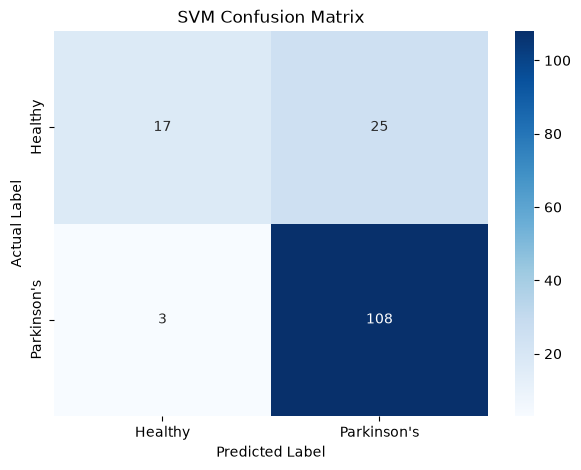

In [10]:
#visualize the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Parkinson's"],
    yticklabels=["Healthy", "Parkinson's"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.show()

The diagonal values represent correct predictions, while the off-diagonal values represent misclassifications. That is the model correctly classify 17 and 108 with pakinson disease. However, 25 healthy were incorrectly classified as with pakinson's disease (false negatives), while 3 with pakinson's disease were incorrectly classified as healthy (false positives).

**Using Grid Search to improve performance**

In [13]:
# Define hyperparameter grid
param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1]
    }
]

# Participant-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# GridSearchCV
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

# Fit on training data only
grid_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", grid_search.best_score_)

Best Parameters: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best Cross-Validation Macro F1: 0.7170746522384006


In [14]:
#Evaluate teh Tuned SVM Model
# Best tuned model
best_svm = grid_search.best_estimator_

# Make predictions
y_pred_tuned = best_svm.predict(X_test)

# Evaluate tuned model
print("Tuned SVM Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("\nTuned Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    labels=[0, 1],
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))

# Tuned confusion matrix
cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=[0, 1]
)

Tuned SVM Accuracy: 0.8169934640522876

Tuned Classification Report:
              precision    recall  f1-score   support

     Healthy       0.85      0.40      0.55        42
 Parkinson's       0.81      0.97      0.89       111

    accuracy                           0.82       153
   macro avg       0.83      0.69      0.72       153
weighted avg       0.82      0.82      0.79       153



After tuning, it did not improve performance beyond the original model a everthing else remained thesame.

**Import RandomizedSearchCV**



In [16]:
param_distributions = [
    {
        "svm__kernel": ["linear"],
        "svm__C": loguniform(0.01, 1000),
        "svm__class_weight": [None, "balanced"]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": loguniform(0.01, 1000),
        "svm__gamma": loguniform(0.0001, 10),
        "svm__class_weight": [None, "balanced"]
    }
]


Note the following:
C controls the trade-off between training errors and regularization
gamma controls how strongly individual training samples influence the RBF decision boundary
Kernl tests linear and nonlinear decision boundaries and 
class_weight tests whether balancing class importance improves classification

In [17]:
#Using f1_macro randomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=svm_pipeline,
    param_distributions=param_distributions,
    n_iter=50,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train using training data only
random_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(random_search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters:
{'svm__C': np.float64(0.011972422479639328), 'svm__class_weight': None, 'svm__kernel': 'linear'}

Best Cross-Validation Macro F1:
0.7272683829225605


**Evaluate the Randomized SVM**


In [18]:
# Get the best model
random_svm = random_search.best_estimator_

# Make predictions
y_pred_random = random_svm.predict(X_test)

# Evaluate
print("RandomizedSearchCV Tuned SVM Accuracy:",
      accuracy_score(y_test, y_pred_random))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_random,
    labels=[0, 1],
    target_names=["Healthy", "Parkinson's"],
    zero_division=0
))

RandomizedSearchCV Tuned SVM Accuracy: 0.8496732026143791

Classification Report:
              precision    recall  f1-score   support

     Healthy       0.76      0.67      0.71        42
 Parkinson's       0.88      0.92      0.90       111

    accuracy                           0.85       153
   macro avg       0.82      0.79      0.80       153
weighted avg       0.85      0.85      0.85       153



After applying RandomizedSearchCV, the optimized SVM model, accuracy increased from 81.70% to 84.97%. This shows an improvement from the original accuracy The healthy-class recall increased significantly from 40% to 67%, while its F1-score improved from 0.55 to 0.71. This indicates that the optimized model was more effective at correctly identifying healthy individuals.